## Моделирование

### 1 Методология и валидация

- **Метрики:** основная — **MAE** (устойчива к пикам энергопотребления, измеряется в Wh), вспомогательная — **RMSE** (сильнее штрафует крупные ошибки, измеряется в Wh).
- **Валидация:** хронологический порядок без перемешивания — отложенный `test` и скользящая кросс-валидация `TimeSeriesSplit` по `train` с выводом среднего и разброса (`mean ± std`) по фолдам.
- **Целевая переменная и защита от утечек:**  масштабирование и обучение моделей выполняются строго внутри каждого фолда / на обучающей выборке. Обучение идёт на логарифмированной цели (`log1p`), а метрики считаются после обратного перевода в исходную шкалу (`expm1`) с ограничением снизу нулём.
- **Модели и регуляризация:** базовые ориентиры (`DummyRegressor`, наивные лаговые прогнозы и `Ridge`) с переходом к линейным моделям с регуляризацией — **Ridge**, **Lasso** и **ElasticNet**  — в связке с масштабированием признаков внутри пайплайна.

### 2 Загрузка данных и подготовка матриц признаков


In [1]:
import time

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import optuna
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [2]:
train_df = pd.read_parquet("../data/processed/train.parquet")
test_df = pd.read_parquet("../data/processed/test.parquet")

print("Train shape:", train_df.shape, "| Test shape:", test_df.shape)
print("Колонки:", list(train_df.columns))

Train shape: (15672, 52) | Test shape: (3919, 52)
Колонки: ['date', 'Appliances', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'RH_out', 'hour', 'weekday', 'is_weekend', 'sin_hour', 'cos_hour', 'shower_diff_10m', 'shower_diff_20m', 'cooking_temp_diff_10m', 'cooking_hum_diff_10m', 'cooking_hum_diff_20m', 'shower_rise_10m', 'shower_rise_20m', 'cooking_hum_rise_20m', 'is_shower_spike_20m', 'is_cooking_spike_20m', 'indoor_temperature_mean', 'indoor_temperature_min', 'indoor_temperature_max', 'indoor_temperature_range', 'indoor_humidity_mean', 'indoor_humidity_min', 'indoor_humidity_max', 'indoor_humidity_range', 'indoor_outdoor_temperature_diff', 'indoor_outdoor_humidity_diff', 'Appliances_lag_1', 'Appliances_lag_2', 'Appliances_lag_3', 'Appliances_lag_144', 'lights_lag_1']


### 3 Подготовка признаков и базовые модели(Baseline)

- Колонки `'date'` и `'Appliances'` исключаем из матрицы признаков `X`.
- Обучение ведём на логарифмированной цели (`log1p`), а при расчёте метрик (`MAE` и `RMSE`) возвращаем предсказания и факт в Wh через обратное преобразование (`expm1`) с ограничением снизу нулём

In [3]:
target_col = "Appliances"
exclude_cols = {"date", target_col}
feature_cols = [c for c in train_df.columns if c not in exclude_cols]

X_train = train_df[feature_cols]
y_train_log = np.log1p(train_df[target_col])

X_test = test_df[feature_cols]
y_test_log = np.log1p(test_df[target_col])

print("Число признаков:", len(feature_cols))

tscv = TimeSeriesSplit(n_splits=5)

def evaluate_cv_log_target(model, X, y_log, cv):
    mae_scores, rmse_scores = [], []
    for tr_idx, val_idx in cv.split(X):
        X_tr, y_tr = X.iloc[tr_idx], y_log.iloc[tr_idx]
        X_val, y_val = X.iloc[val_idx], y_log.iloc[val_idx]

        model.fit(X_tr, y_tr)
        pred_val_log = model.predict(X_val)

        y_val_wh = np.clip(np.expm1(y_val), 0, None)
        pred_val_wh = np.clip(np.expm1(pred_val_log), 0, None)

        mae_scores.append(mean_absolute_error(y_val_wh, pred_val_wh))
        rmse_scores.append(root_mean_squared_error(y_val_wh, pred_val_wh))

    return {
        "MAE_mean": np.mean(mae_scores),
        "MAE_std": np.std(mae_scores),
        "RMSE_mean": np.mean(rmse_scores),
        "RMSE_std": np.std(rmse_scores),
    }

baseline_models = {
    "Dummy (median)": DummyRegressor(strategy="median"),
    "Ridge (alpha=10.0, scaled)": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
}

rows = []
for name, model in baseline_models.items():
    res = evaluate_cv_log_target(model, X_train, y_train_log, tscv)
    res["Model"] = name
    rows.append(res)

baseline_df = pd.DataFrame(rows)[
    ["Model", "MAE_mean", "MAE_std", "RMSE_mean", "RMSE_std"]
]
display(baseline_df)

Число признаков: 50


,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,Dummy (median),50.911945,4.198240,109.827844,5.681386
1,"Ridge (alpha=10.0, scaled)",34.297062,2.766627,86.403902,7.079601


In [4]:
naive_maes, naive_rmses = [], []
y_train_wh = np.expm1(y_train_log)

for train_idx, val_idx in tscv.split(X_train):
    # Без np.expm1, так как lag_1 уже в Wh
    y_val_pred_wh = X_train.iloc[val_idx]["Appliances_lag_1"]
    y_val_true_wh = y_train_wh.iloc[val_idx]

    # Убираем строки с NaN, если такие есть
    mask = y_val_pred_wh.notna() & y_val_true_wh.notna()
    y_pred_clean = y_val_pred_wh[mask]
    y_true_clean = y_val_true_wh[mask]

    naive_maes.append(mean_absolute_error(y_true_clean, y_pred_clean))
    naive_rmses.append(root_mean_squared_error(y_true_clean, y_pred_clean))

print(f"Наивный бейзлайн (lag_1) | MAE: {np.mean(naive_maes):.4f} ± {np.std(naive_maes):.4f} Wh")
print(f"Наивный бейзлайн (lag_1) | RMSE: {np.mean(naive_rmses):.4f} ± {np.std(naive_rmses):.4f} Wh")

Наивный бейзлайн (lag_1) | MAE: 30.2619 ± 1.5819 Wh
Наивный бейзлайн (lag_1) | RMSE: 73.0068 ± 2.1144 Wh


In [5]:
lag144_maes, lag144_rmses = [], []
y_train_wh = np.expm1(y_train_log)

for train_idx, val_idx in tscv.split(X_train):
    # Без np.expm1, так как lag_144 уже в Wh
    y_val_pred_wh = X_train.iloc[val_idx]["Appliances_lag_144"]
    y_val_true_wh = y_train_wh.iloc[val_idx]

    # Убираем строки с NaN, если такие есть
    mask = y_val_pred_wh.notna() & y_val_true_wh.notna()
    y_pred_clean = y_val_pred_wh[mask]
    y_true_clean = y_val_true_wh[mask]

    lag144_maes.append(mean_absolute_error(y_true_clean, y_pred_clean))
    lag144_rmses.append(root_mean_squared_error(y_true_clean, y_pred_clean))

print(f"Бейзлайн (lag_144, сутки назад) | MAE: {np.mean(lag144_maes):.4f} ± {np.std(lag144_maes):.4f} Wh")
print(f"Бейзлайн (lag_144, сутки назад) | RMSE: {np.mean(lag144_rmses):.4f} ± {np.std(lag144_rmses):.4f} Wh")

Бейзлайн (lag_144, сутки назад) | MAE: 64.1983 ± 3.8896 Wh
Бейзлайн (lag_144, сутки назад) | RMSE: 128.4878 ± 5.2436 Wh


- **Константный ориентир (`DummyRegressor`):** на 50 признаках при разбиении `TimeSeriesSplit` медианное предсказание даёт `MAE = 50.91 ± 4.20 Wh` и `RMSE = 109.83 ± 5.68 Wh`.
- **Базовая линейная модель (`Ridge`, `alpha=10.0`):** в связке со `StandardScaler` внутри пайплайна снижает ошибку до `MAE = 34.30 ± 2.77 Wh` и `RMSE = 86.40 ± 7.08 Wh`
- **Наивные бейзлайны по лагам:** прогноз «как 10 минут назад» (Appliances_lag_1) заметно снижает ошибку (MAE ≈ 30.26 ± 1.58 Wh, RMSE ≈ 73.01 ± 2.11 Wh) за счёт высокой краткосрочной инерции потребления, тогда как прогноз «как сутки назад» (Appliances_lag_144) ошибается сильнее (MAE ≈ 64.20 ± 3.89 Wh, RMSE ≈ 128.49 ± 5.24 Wh), поскольку бытовые события и нагрузки меняются день ото дня.
- **Чистота валидации:** масштабирование и обучение выполняются строго внутри каждого фолда, поэтому утечек данных нет.
- **Следующий шаг:** подобрать гиперпараметр `alpha` для `Ridge` (по сетке и через `Optuna`), сравнить виды регуляризации и оценить влияние масштабирования.

### 4 Подбор гиперпараметров alpha  для Ridge-модели (сетка и Optuna)

In [6]:
alphas = [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 500.0]
tuning_rows = []

for alpha in alphas:
    pipe = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    res = evaluate_cv_log_target(pipe, X_train, y_train_log, tscv)
    res["alpha"] = alpha
    tuning_rows.append(res)

tuning_df = pd.DataFrame(tuning_rows)[
    ["alpha", "MAE_mean", "MAE_std", "RMSE_mean", "RMSE_std"]
].sort_values("MAE_mean")

display(tuning_df)

best_grid_alpha = tuning_df.iloc[0]["alpha"]
best_grid_mae = tuning_df.iloc[0]["MAE_mean"]
baseline_mae = baseline_df.loc[
    baseline_df["Model"] == "Ridge (alpha=10.0, scaled)", "MAE_mean"
].iloc[0]

print(f"Лучший alpha по сетке: {best_grid_alpha}")
print(f"MAE изменился с {baseline_mae:.4f} на {best_grid_mae:.4f} Wh (разница: {best_grid_mae - baseline_mae:+.4f} Wh)")

,alpha,MAE_mean,MAE_std,RMSE_mean,RMSE_std
6,500.00,32.876427,2.068482,79.289576,4.219224
5,100.00,33.530287,2.002203,83.237839,5.236645
4,50.00,33.808786,2.204594,84.574465,5.724503
3,10.00,34.297062,2.766627,86.403902,7.079601
2,1.00,34.674468,3.365611,87.327560,8.188357
1,0.10,34.749481,3.495348,87.484178,8.406396
0,0.01,34.757744,3.509776,87.501325,8.430736


Лучший alpha по сетке: 500.0
MAE изменился с 34.2971 на 32.8764 Wh (разница: -1.4206 Wh)


In [7]:
def objective(trial):
    alpha = trial.suggest_float("alpha", 1e-3, 1e3, log=True)
    pipe = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    res = evaluate_cv_log_target(pipe, X_train, y_train_log, tscv)
    return res["MAE_mean"]

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="minimize", sampler=sampler)
optuna.logging.set_verbosity(optuna.logging.WARNING)
study.optimize(objective, n_trials=40)

best_optuna_alpha = study.best_params["alpha"]
best_optuna_mae = study.best_value

best_optuna_pipe = make_pipeline(StandardScaler(), Ridge(alpha=best_optuna_alpha))
best_optuna_metrics = evaluate_cv_log_target(best_optuna_pipe, X_train, y_train_log, tscv)

print(f"Лучший alpha по Optuna: {best_optuna_alpha:.4f}")
print(
    f"MAE: {best_optuna_metrics['MAE_mean']:.4f} ± {best_optuna_metrics['MAE_std']:.4f} Wh | "
    f"RMSE: {best_optuna_metrics['RMSE_mean']:.4f} ± {best_optuna_metrics['RMSE_std']:.4f} Wh"
)
print(
    f"Изменение MAE относительно baseline (alpha=10.0): "
    f"{best_optuna_metrics['MAE_mean'] - baseline_mae:+.4f} Wh"
)

[I 2026-11-24 06:40:33,035] A new study created in memory with name: no-name-e15193b9-db6e-4219-934c-b7a35c369bb4


Лучший alpha по Optuna: 663.7076
MAE: 32.8381 ± 2.2548 Wh | RMSE: 78.6805 ± 4.0293 Wh
Изменение MAE относительно baseline (alpha=10.0): -1.4590 Wh


- Подбор по сетке и оптимизация через `Optuna` (`TPESampler`) показывают, что более сильная регуляризация (оптимум около `alpha ≈ 663.71`) снижает ошибку на `TimeSeriesSplit` по сравнению с базовым `alpha=10.0`.
- Средний `MAE` уменьшается примерно с `34.30 Wh` до `32.84 Wh`, а `RMSE` — с `86.40 Wh` до `78.68 Wh`.

### 5 Влияние масштабирования признаков

In [8]:
scalers = {
    "No scaling": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
}

scale_rows = []
coefs_by_scaler = {}

for name, scaler in scalers.items():
    if scaler is None:
        model = Ridge(alpha=best_optuna_alpha)
    else:
        model = make_pipeline(scaler, Ridge(alpha=best_optuna_alpha))

    res = evaluate_cv_log_target(model, X_train, y_train_log, tscv)
    res["Scaler"] = name

    # Обучаем на полном train (в логарифмированной цели) для анализа коэффициентов
    model.fit(X_train, y_train_log)
    ridge_est = model.named_steps["ridge"] if hasattr(model, "named_steps") else model
    coefs = pd.Series(ridge_est.coef_, index=feature_cols)
    coefs_by_scaler[name] = coefs

    res["n_coefs"] = len(coefs)
    res["max_abs_coef"] = coefs.abs().max()
    res["mean_abs_coef"] = coefs.abs().mean()
    scale_rows.append(res)

scale_df = pd.DataFrame(scale_rows)[
    ["Scaler", "MAE_mean", "MAE_std", "RMSE_mean", "RMSE_std", "n_coefs", "mean_abs_coef", "max_abs_coef"]
]
display(scale_df)

# Топ-5 признаков по модулю коэффициента для каждого варианта
for name, coefs in coefs_by_scaler.items():
    print(f"\n--- {name}: топ-5 признаков по |coef| ---")
    display(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(5))

,Scaler,MAE_mean,MAE_std,RMSE_mean,RMSE_std,n_coefs,mean_abs_coef,max_abs_coef
0,No scaling,34.148852,2.503306,88.300801,6.841187,50,0.012816,0.127437
1,StandardScaler,32.838053,2.254802,78.680456,4.029340,50,0.024692,0.379617
2,MinMaxScaler,42.679642,3.325434,95.221582,5.392677,50,0.085219,0.665968



--- No scaling: топ-5 признаков по |coef| ---


cos_hour               -0.127437
sin_hour               -0.078620
T8                      0.050341
cooking_hum_diff_20m   -0.036012
cooking_hum_diff_10m   -0.029849
dtype: float64


--- StandardScaler: топ-5 признаков по |coef| ---


Appliances_lag_1    0.379617
cos_hour           -0.094952
sin_hour           -0.070073
Appliances_lag_3    0.069532
T8                  0.069137
dtype: float64


--- MinMaxScaler: топ-5 признаков по |coef| ---


Appliances_lag_1    0.665968
Appliances_lag_2    0.432766
Appliances_lag_3    0.343866
cos_hour           -0.330378
lights_lag_1        0.265005
dtype: float64

- **Качество на кросс-валидации:** лучший результат показал `StandardScaler` (`MAE ≈ 32.84 ± 2.25 Wh`, `RMSE ≈ 78.68 ± 4.03 Wh`). Вариант без масштабирования (`No scaling`) уступил (`MAE ≈ 34.15 Wh`, `RMSE ≈ 88.30 Wh`), а `MinMaxScaler` ухудшил метрики (`MAE ≈ 42.68 Wh`, `RMSE ≈ 95.22 Wh`), вероятно из-за чувствительности диапазона `[0, 1]` к пиковым значениям.
- **Важные признаки:** при `StandardScaler` наибольший вес получает `Appliances_lag_1` вместе с суточными гармониками (`cos_hour`, `sin_hour`), `Appliances_lag_3` и `T8`.
- **Итог:** оставляем `StandardScaler` в пайплайне с регуляризацией и подобранным `alpha`.

### 6 Сравнение регуляризаций: Lasso и ElasticNet

#### Lasso (L1-регуляризация)

In [9]:

print("Обучение Lasso (L1-регуляризация)...")
start_time = time.time()

# 1. Создаем пайплайн с Lasso (используем то же пространство alpha, но Lasso чувствительнее)
# Нам нужно подобрать alpha для Lasso. Сделаем быстрый перебор по сетке.
lasso_alphas = [0.0001, 0.001, 0.01, 0.1]
best_lasso_alpha = None
best_lasso_mae = float('inf')

for a in lasso_alphas:
    pipe_lasso = make_pipeline(StandardScaler(), Lasso(alpha=a, random_state=42, max_iter=20000))
    res_lasso = evaluate_cv_log_target(pipe_lasso, X_train, y_train_log, tscv)
    
    if res_lasso['MAE_mean'] < best_lasso_mae:
        best_lasso_mae = res_lasso['MAE_mean']
        best_lasso_alpha = a

# 2. Обучаем финальную Lasso с лучшим alpha
final_lasso = make_pipeline(StandardScaler(), Lasso(alpha=best_lasso_alpha, random_state=42, max_iter=20000))
res_final_lasso = evaluate_cv_log_target(final_lasso, X_train, y_train_log, tscv)

print(f"Лучший alpha для Lasso: {best_lasso_alpha}")
print(f"MAE Lasso на CV: {res_final_lasso['MAE_mean']:.2f} Wh")
print(f"Lasso RMSE (CV): {res_final_lasso['RMSE_mean']:.2f} ± {res_final_lasso['RMSE_std']:.2f} Wh")
print(f"Сколько признаков занулил Lasso: {(final_lasso.named_steps['lasso'].coef_ == 0).sum()} из {len(X_train.columns)}")

Обучение Lasso (L1-регуляризация)...
Лучший alpha для Lasso: 0.01
MAE Lasso на CV: 33.53 Wh
Lasso RMSE (CV): 84.56 ± 5.46 Wh
Сколько признаков занулил Lasso: 31 из 50


#### ElasticNet (L1 + L2)

In [10]:

elastic_configs = [
    {"alpha": 0.01, "l1_ratio": 0.2},
    {"alpha": 0.01, "l1_ratio": 0.5},
    {"alpha": 0.01, "l1_ratio": 0.8},
    {"alpha": 0.1, "l1_ratio": 0.5},
]

en_rows = []
for cfg in elastic_configs:
    pipe_en = make_pipeline(
        StandardScaler(),
        ElasticNet(
            alpha=cfg["alpha"],
            l1_ratio=cfg["l1_ratio"],
            random_state=42,
            max_iter=5000,
        ),
    )
    res = evaluate_cv_log_target(pipe_en, X_train, y_train_log, tscv)
    res["alpha"] = cfg["alpha"]
    res["l1_ratio"] = cfg["l1_ratio"]
    en_rows.append(res)

en_df = pd.DataFrame(en_rows)[
    ["alpha", "l1_ratio", "MAE_mean", "MAE_std", "RMSE_mean", "RMSE_std"]
].sort_values("MAE_mean")
display(en_df)

,alpha,l1_ratio,MAE_mean,MAE_std,RMSE_mean,RMSE_std
1,0.01,0.5,33.437058,2.292818,84.048312,5.307318
3,0.10,0.5,33.446943,2.837676,79.299844,3.792966
0,0.01,0.2,33.463598,2.218700,84.226194,5.687136
2,0.01,0.8,33.512403,2.426270,84.317135,5.378072


- **`Lasso`:** зануляет часть признаков (31 из 50 при `alpha=0.01`), давая `MAE ≈ 33.53 Wh` и `RMSE ≈ 84.56 Wh`на кросс-валидации.
- **`ElasticNet` :** сочетает отбор/разреживание признаков и сглаживание весов; лучшая проверенная комбинация (`alpha=0.01, l1_ratio=0.5`) показала `MAE ≈ 33.44 Wh`.
- **Итог сравнения:** по метрике `MAE` на кросс-валидации обе модели уступают `Ridge` (`MAE ≈ 32.84 Wh`), поэтому для финального прогноза оставляем `Ridge` со `StandardScaler`.

### 7 Финальное обучение и проверка на отложенном тесте

In [11]:
final_model = make_pipeline(StandardScaler(), Ridge(alpha=best_optuna_alpha))
final_model.fit(X_train, y_train_log)

pred_test_log = final_model.predict(X_test)

y_test_wh = np.clip(np.expm1(y_test_log), 0, None)
pred_test_wh = np.clip(np.expm1(pred_test_log), 0, None)

test_mae = mean_absolute_error(y_test_wh, pred_test_wh)
test_rmse = root_mean_squared_error(y_test_wh, pred_test_wh)

print(f"Финальная модель: StandardScaler + Ridge(alpha={best_optuna_alpha:.4f})")
print(f"Test MAE:  {test_mae:.4f} Wh")
print(f"Test RMSE: {test_rmse:.4f} Wh")

Финальная модель: StandardScaler + Ridge(alpha=663.7076)
Test MAE:  27.6624 Wh
Test RMSE: 68.8322 Wh


- Финальная модель `StandardScaler + Ridge (alpha ≈ 663.71)` на отложенной тестовой выборке показала `Test MAE = 27.66 Wh` и `Test RMSE = 68.83 Wh`.
- Качество на тесте не хуже результатов кросс-валидации (`CV MAE ≈ 32.84 Wh`, `CV RMSE ≈ 78.68 Wh`), что подтверждает отсутствие переобучения и устойчивость модели на новых данных во времени.

### 8 Интерпретация финальной модели

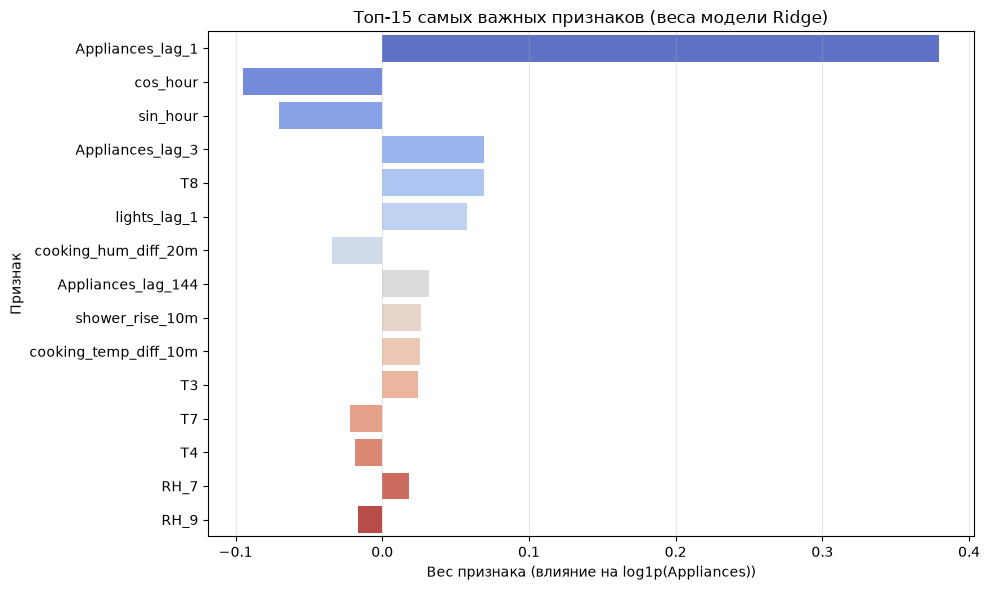

In [12]:

# Коэффициенты финальной модели Ridge после StandardScaler
final_coefs = pd.Series(
    final_model.named_steps["ridge"].coef_, index=X_train.columns
)
# Сортируем по модулю (самые важные сверху/снизу)
top_coefs = final_coefs.sort_values(key=abs, ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_coefs.values, y=top_coefs.index, hue=top_coefs.index, palette='coolwarm', legend=False)
plt.title('Топ-15 самых важных признаков (веса модели Ridge)')
plt.xlabel('Вес признака (влияние на log1p(Appliances))')
plt.ylabel('Признак')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

- **Главный предиктор:** Наибольший вес имеет лаг Appliances_lag_1. Модель подтвердила, что для прогноза будущего потребления критически важно знать, сколько энергии тратилось 10 минут назад.
- **Время суток:** Циклические признаки sin_hour и cos_hour занимают второе место по важности. Модель успешно выучила суточный профиль активности (дневные и вечерние пики).
- **События и маркеры:** Созданные нами признаки изменения влажности/температуры (готовка, душ) и лаг света (lights_lag_1) попали в топ. Это доказывает, что наш Feature Engineering был успешным — модель использует эти сигналы для прогноза.
- **Регуляризация:** Некоторые признаки получили небольшие или отрицательные веса (T4, RH_7, RH_9), а L_2-штраф сгладил веса и уменьшил влияние лишних колебаний без жёсткого обнуления

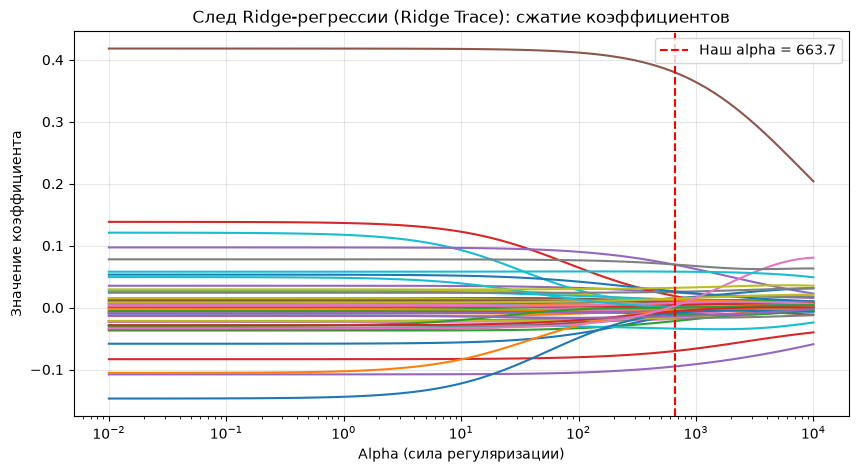

In [13]:

alphas = np.logspace(-2, 4, 100) # от 0.01 до 10000
coefs = []

# Обучаем модель для каждого alpha и запоминаем коэффициенты
for a in alphas:
    ridge = Ridge(alpha=a)
    # Обучаем на стандартизированных данных, чтобы коэффициенты были сопоставимы
    ridge.fit(final_model.named_steps['standardscaler'].transform(X_train), y_train_log)
    coefs.append(ridge.coef_)

plt.figure(figsize=(10, 5))
plt.plot(alphas, coefs)
plt.xscale('log') # Логарифмическая шкала по X
plt.axvline(x=best_optuna_alpha, color='red', linestyle='--', label=f'Наш alpha = {best_optuna_alpha:.1f}')
plt.xlabel('Alpha (сила регуляризации)')
plt.ylabel('Значение коэффициента')
plt.title('След Ridge-регрессии (Ridge Trace): сжатие коэффициентов')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Валидация регуляризации (Ridge Trace):
График демонстрирует процесс сжатия коэффициентов модели при увеличении параметра регуляризации alpha. Каждая цветная линия — это вес отдельного признака.

- При малых значениях alpha (слева) веса крупные и модель сильнее реагирует на частные колебания
-  При больших значениях alpha (справа) все коэффициенты стремятся к нулю (модель становится слишком простой).
- Красная пунктирная линия показывает alpha = 663.7, найденный с помощью Optuna. Это оптимальная точка баланса (bias-variance tradeoff), где важные признаки (например, лаги, верхняя кривая) сохраняют вес, а шумные признаки (скопление линий около нуля) эффективно подавляются.

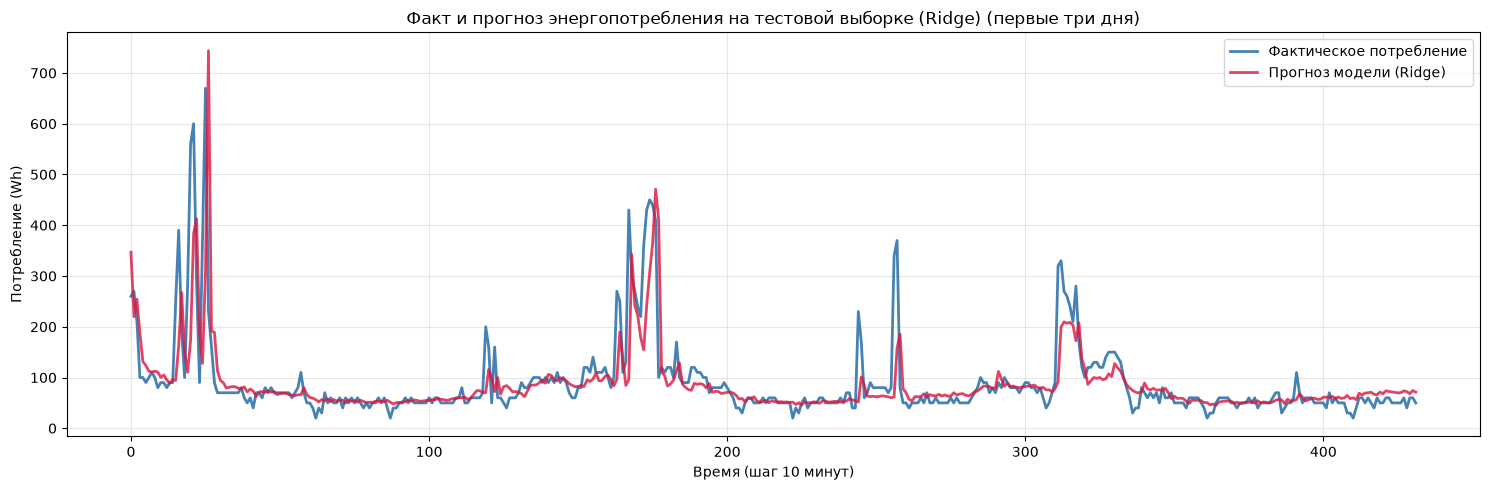

In [14]:
# Берем для отображения только первые 3 дня теста (примерно 432 точки по 10 минут)
# Иначе график будет слишком плотным и нечитаемым
plot_days = 3 * 24 * 6 
y_actual_plot = y_test_wh[:plot_days]
y_pred_plot = pred_test_wh[:plot_days]

plt.figure(figsize=(15, 5))

# Рисуем факт и прогноз
plt.plot(y_actual_plot, label='Фактическое потребление', color='steelblue', linewidth=2)
plt.plot(y_pred_plot, label='Прогноз модели (Ridge)', color='crimson', linewidth=2, alpha=0.8)

plt.title("Факт и прогноз энергопотребления на тестовой выборке (Ridge) (первые три дня)")
plt.xlabel('Время (шаг 10 минут)')
plt.ylabel('Потребление (Wh)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


На фрагментах первых трех дней модель хорошо повторяет базовый уровень и суточный ход энергопотребления, но сглаживает редкие резкие пики — именно этим объясняется более высокое значение `RMSE` (`68.83 Wh`) по сравнению с `MAE` (`27.66 Wh`).


#### Общие выводы 

- **Что сделали:** построили бейзлайны (`DummyRegressor`, наивные ориентиры по `lag_1`и`lag_144`, а также базовый `Ridge`), подобрали силу регуляризации `alpha` по сетке и через `Optuna` на хронологической кросс-валидации `TimeSeriesSplit`, сравнили способы масштабирования (`No scaling`, `StandardScaler`, `MinMaxScaler`) и проверили разные типы регуляризации (`Ridge`, `Lasso`, `ElasticNet`) с оценкой метрик в реальных `Wh` (`log1p` → `expm1`).
- **Какой способ показал лучший результат:** связка `StandardScaler` + `Ridge` с подобранным `alpha ≈ 663.71` показала наилучшее качество на кросс-валидации (`MAE ≈ 32.84 Wh`, `RMSE ≈ 78.68 Wh`) и обошла `Lasso` (`MAE ≈ 33.53 Wh`, обнулено 31 из 50 признаков) и `ElasticNet` (`MAE ≈ 33.44 Wh` для лучшей проверенной конфигурации `alpha=0.01, l1_ratio=0.5`).
- **Проверка на отложенном тесте:** финальная модель `StandardScaler + Ridge (alpha ≈ 663.71)` на тестовой выборке показала `MAE = 27.66 Wh` и `RMSE = 68.83 Wh`, подтверждая устойчивость без переобучения и утечек данных.
- **Ключевые признаки:** наибольший вклад в прогноз вносят лаги потребления, суточные гармоники времени и температура в помещениях; модель хорошо ловит общий ритм, но сглаживает редкие резкие пики (что видно на фрагменте первых 3 дней теста и по разнице между `MAE` и `RMSE`).
- **Нужно добавить** эксперименты с деревьями решений и ансамблями  на той же схеме валидации `TimeSeriesSplit`